In [13]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


# Style configurations for clear, publication-quality plots
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['figure.figsize'] = (10, 5)
plt.rcParams['font.size'] = 11


In [4]:
data_path = '../data/data.csv'

# load the raw dataset
df_raw = pd.read_csv(data_path)

# verify shape and customer count
total_customers, total_cols = df_raw.shape
print(f"Dataset Shape: {df_raw.shape}")
print(f"Total Customers (Rows): {total_customers:,}")
print(f"Total Columns: {total_cols:,}")

Dataset Shape: (42372, 1036)
Total Customers (Rows): 42,372
Total Columns: 1,036


In [19]:
# Check Class Imbalance

class_counts = df_raw['FLAG'].value_counts()

class_percentage = df_raw['FLAG'].value_counts(normalize=True) * 100

#create class summary
class_summary = pd.DataFrame({
    'Count': class_counts,
    'Percentage (%)': class_percentage.round(2)
})

#update index
class_summary.index = ['Normal', 'Theft']

print(class_summary)


imbalance_ratio = class_counts[0] / class_counts[1]

print(f"\nImbalance Ratio: {imbalance_ratio:.2f} normal customers for every 1 thief.")

        Count  Percentage (%)
Normal  38757           91.47
Theft    3615            8.53

Imbalance Ratio: 10.72 normal customers for every 1 thief.


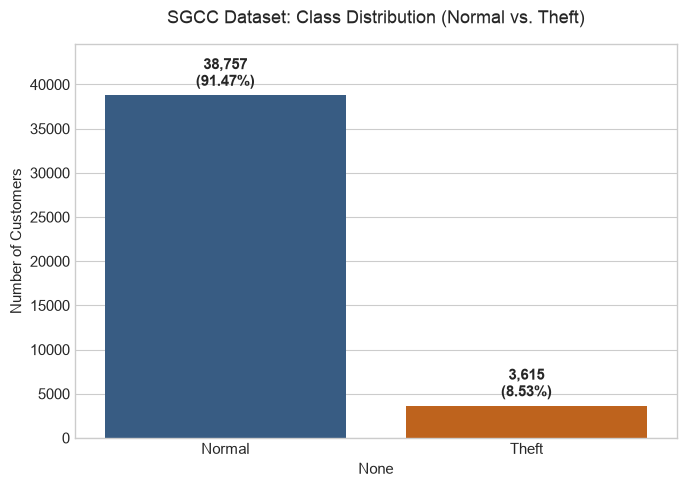

In [17]:
# plot class balance

plt.figure(figsize=(7, 5))
palette = ['#2b5c8f', '#d95f02']

# assign hue=class_summary.index and legend=False to prevent the deprecation warning
ax = sns.barplot(
    x=class_summary.index, 
    y=class_summary['Count'], 
    hue=class_summary.index, 
    palette=palette, 
    legend=False
)

# Annotate counts and percentages on top of bars
for i, (count, pct) in enumerate(zip(class_summary['Count'], class_summary['Percentage (%)'])):
    ax.text(i, count + 600, f"{count:,}\n({pct}%)", ha='center', va='bottom', fontweight='bold')

plt.title('SGCC Dataset: Class Distribution (Normal vs. Theft)', fontsize=13, pad=15)
plt.ylabel('Number of Customers')
plt.ylim(0, max(class_summary['Count']) * 1.15)
plt.tight_layout()
plt.show()


In [20]:
# sort date columns & identify missing day

# Separate metadata columns from date columns
meta_cols = ['CONS_NO', 'FLAG']
date_cols_raw = [col for col in df_raw.columns if col not in meta_cols]

# Parse and sort columns by actual calendar date
sorted_date_cols = sorted(date_cols_raw, key=lambda d: pd.to_datetime(d))

# Reorder dataframe columns chronologically
df_chronological = df_raw[meta_cols + sorted_date_cols]

# Find date bounds
start_date = pd.to_datetime(sorted_date_cols[0])
end_date = pd.to_datetime(sorted_date_cols[-1])
print(f"Date Range: {start_date.strftime('%Y-%m-%d')} to {end_date.strftime('%Y-%m-%d')}")
print(f"Number of recorded date columns: {len(sorted_date_cols)}")

# Generate full expected calendar sequence
full_calendar = pd.date_range(start=start_date, end=end_date, freq='D')
print(f"Expected days in calendar sequence: {len(full_calendar)}")

# Identify missing days
recorded_dates_set = set(pd.to_datetime(sorted_date_cols))
missing_days = [d.strftime('%Y-%m-%d (%d %B %Y)') for d in full_calendar if d not in recorded_dates_set]

print(f"\nMissing Day(s) Detected: {len(missing_days)}")
for day in missing_days:
    print(f" -> {day}")

# Verification check required by assignment
assert any('2016-09-18' in d for d in missing_days), "Missing day 18 September 2016 was not found!"
print("\n[VERIFIED]: Missing date 18 September 2016 successfully identified.")


Date Range: 2014-01-01 to 2016-10-31
Number of recorded date columns: 1034
Expected days in calendar sequence: 1035

Missing Day(s) Detected: 1
 -> 2016-09-18 (18 September 2016)

[VERIFIED]: Missing date 18 September 2016 successfully identified.


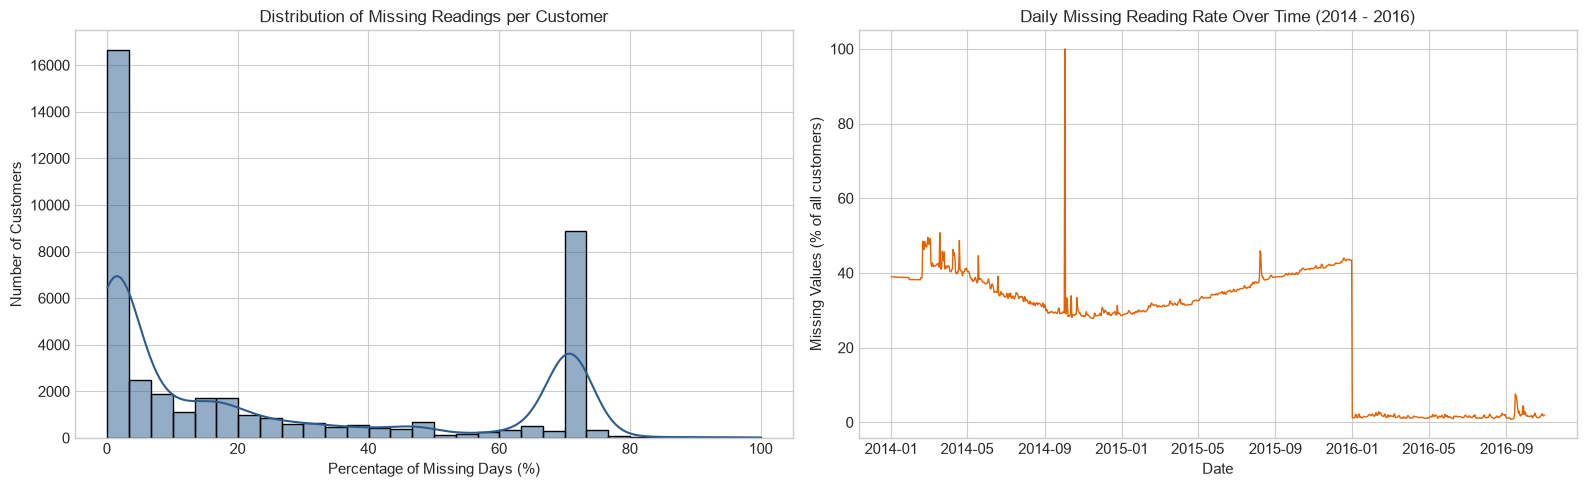

Customers with 100% missing readings: 5


In [25]:
# missing data analysis

# 1. Missingness per customer (along rows)
customer_missing_percentage = df_chronological[sorted_date_cols].isna().mean(axis=1) * 100

# 2. Missingness per date (along columns)
date_missing_pct = df_chronological[sorted_date_cols].isna().mean(axis=0) * 100
date_missing_series = pd.Series(date_missing_pct.values, index=pd.to_datetime(sorted_date_cols))

# Create dual plot
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# Plot A: Customer missing data histogram
sns.histplot(customer_missing_percentage, bins=30, kde=True, color='#2b5c8f', ax=axes[0])
axes[0].set_title('Distribution of Missing Readings per Customer', fontsize=12)
axes[0].set_xlabel('Percentage of Missing Days (%)')
axes[0].set_ylabel('Number of Customers')

# Plot B: Daily missingness over time
axes[1].plot(date_missing_series.index, date_missing_series.values, color='#e66101', linewidth=1)
axes[1].set_title('Daily Missing Reading Rate Over Time (2014 - 2016)', fontsize=12)
axes[1].set_xlabel('Date')
axes[1].set_ylabel('Missing Values (% of all customers)')

plt.tight_layout()
plt.show()

# Check customers with 100% missing readings
completely_empty = (customer_missing_percentage == 100).sum()
print(f"Customers with 100% missing readings: {completely_empty:,}")


In [22]:
# data cleaning
# drop customers with no usable readings
print(f"Customer count before filtering: {len(df_chronological):,}")

# Identify customers who have at least ONE positive consumption reading (> 0)
has_usable_readings = (df_chronological[sorted_date_cols].fillna(0) > 0).any(axis=1)

# Filter dataset
df_usable = df_chronological[has_usable_readings].copy()

dropped_empty_count = len(df_chronological) - len(df_usable)
print(f"Dropped {dropped_empty_count:,} customers with no usable readings.")
print(f"Customer count remaining: {len(df_usable):,}")





#fill single-day gaps


Customer count before filtering: 42,372
Dropped 2,114 customers with no usable readings.
Customer count remaining: 40,258

[VERIFIED]: Exactly 40,258 customers remain.


In [24]:
# remove duplicates

# Check for identical consumption time series profiles
duplicate_mask = df_usable.duplicated(subset=sorted_date_cols, keep='first')
duplicate_count = duplicate_mask.sum()

print(f"Duplicate consumption profiles found: {duplicate_count}")

# Remove the duplicates
df_dedup = df_usable[~duplicate_mask].copy()

print(f"Customer count after removing duplicates: {len(df_dedup):,}")



Duplicate consumption profiles found: 2
Customer count after removing duplicates: 40,256


In [27]:
# cap extreme spikes (Outlier Capping)

# Extract the numeric values for date columns
consumption_matrix = df_dedup[sorted_date_cols].values.copy()

print(f"Maximum raw consumption value observed: {np.nanmax(consumption_matrix):,.2f} kWh")

# Compute per-customer mean and standard deviation (ignoring NaNs)
customer_means = np.nanmean(consumption_matrix, axis=1, keepdims=True)
customer_stds = np.nanstd(consumption_matrix, axis=1, keepdims=True)

# Upper bound: mean + 3 * std (standard 3-sigma capping rule)
upper_bounds = customer_means + 3 * customer_stds

# Count how many spike readings exceed the 3-sigma threshold
spikes_mask = (consumption_matrix > upper_bounds) & ~np.isnan(consumption_matrix)
total_spikes_capped = np.sum(spikes_mask)
print(f"Total extreme spike readings detected and capped: {total_spikes_capped:,}")

# Cap spikes at the upper bound
consumption_matrix_capped = np.where(spikes_mask, upper_bounds, consumption_matrix)
print(f"Maximum consumption value after capping: {np.nanmax(consumption_matrix_capped):,.2f} kWh")

# Put capped values back into dataframe
df_capped = df_dedup.copy()
df_capped[sorted_date_cols] = consumption_matrix_capped


Maximum raw consumption value observed: 800,003.32 kWh
Total extreme spike readings detected and capped: 391,638
Maximum consumption value after capping: 84,792.08 kWh


In [28]:
# Fill Single-Day Gaps (Linear Interpolation)

# Check total missing values before gap filling
missing_before = df_capped[sorted_date_cols].isna().sum().sum()

# Interpolate single-day gaps along each row (axis=1, limit=1)
# Note: df_capped[sorted_date_cols] is already sorted chronologically
df_imputed_dates = df_capped[sorted_date_cols].interpolate(method='linear', axis=1, limit=1)

missing_after = df_imputed_dates.isna().sum().sum()
gaps_filled = missing_before - missing_after

print(f"Missing readings before interpolation: {missing_before:,}")
print(f"Missing readings filled (one day per gap):   {gaps_filled:,}")
print(f"Remaining missing readings:             {missing_after:,}")

# Reassemble final cleaned DataFrame
df_cleaned = df_capped.copy()
df_cleaned[sorted_date_cols] = df_imputed_dates



Missing readings before interpolation: 10,477,130
Missing readings filled (one day per gap):   208,627
Remaining missing readings:             10,268,503


In [30]:
# Save cleaned dataset
output_clean_path = '../data/data_cleaned.csv'
print(f"Saving cleaned dataset to {output_clean_path}...")

df_cleaned.to_csv(output_clean_path, index=False)
print(f"[DONE]: Cleaned dataset saved. Final dimensions: {df_cleaned.shape}")

Saving cleaned dataset to ../data/data_cleaned.csv...
[DONE]: Cleaned dataset saved. Final dimensions: (40256, 1036)


In [31]:

#data split

from sklearn.model_selection import train_test_split, StratifiedKFold

# Separate features X (all customer rows) and target y (FLAG)
X = df_cleaned[['CONS_NO']]  # Keep customer identifier
y = df_cleaned['FLAG']

# Perform Stratified 70/30 split with fixed random_state for exact reproducibility
train_idx, test_idx = train_test_split(
    df_cleaned.index,
    test_size=0.30,
    stratify=y,
    random_state=42
)

df_train = df_cleaned.loc[train_idx].copy()
df_test = df_cleaned.loc[test_idx].copy()

# Verification check against assignment specification
print(f"Total Cleaned Customers: {len(df_cleaned):,}")
print(f"Training Set Size:        {len(df_train):,} (Target: ~28,179)")
print(f"Test Set Size:            {len(df_test):,} (Target: ~12,077)")

assert len(df_train) == 28179, f"Expected 28,179 train samples, got {len(df_train)}"
assert len(df_test) == 12077, f"Expected 12,077 test samples, got {len(df_test)}"
print("\n[VERIFIED]: Exact 70/30 split (28,179 / 12,077) achieved.")


Total Cleaned Customers: 40,256
Training Set Size:        28,179 (Target: ~28,179)
Test Set Size:            12,077 (Target: ~12,077)

[VERIFIED]: Exact 70/30 split (28,179 / 12,077) achieved.


In [32]:

# Verify Class Balance Across Train and Test Sets

train_theft_rate = (df_train['FLAG'] == 1).mean() * 100
test_theft_rate = (df_test['FLAG'] == 1).mean() * 100
overall_theft_rate = (df_cleaned['FLAG'] == 1).mean() * 100

split_comparison = pd.DataFrame({
    'Total Samples': [len(df_cleaned), len(df_train), len(df_test)],
    'Normal Count (0)': [
        (df_cleaned['FLAG'] == 0).sum(),
        (df_train['FLAG'] == 0).sum(),
        (df_test['FLAG'] == 0).sum()
    ],
    'Theft Count (1)': [
        (df_cleaned['FLAG'] == 1).sum(),
        (df_train['FLAG'] == 1).sum(),
        (df_test['FLAG'] == 1).sum()
    ],
    'Theft Ratio (%)': [
        round(overall_theft_rate, 3),
        round(train_theft_rate, 3),
        round(test_theft_rate, 3)
    ]
}, index=['Cleaned Dataset', 'Train Set (70%)', 'Test Set (30%)'])

print(split_comparison)


                 Total Samples  Normal Count (0)  Theft Count (1)  \
Cleaned Dataset          40256             36677             3579   
Train Set (70%)          28179             25674             2505   
Test Set (30%)           12077             11003             1074   

                 Theft Ratio (%)  
Cleaned Dataset            8.891  
Train Set (70%)            8.890  
Test Set (30%)             8.893  


In [34]:
# Initialize 5-fold Stratified K-Fold
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# Build a clean, dedicated split dataframe to avoid DataFrame fragmentation
split_info = pd.DataFrame({
    'CONS_NO': df_cleaned['CONS_NO'].values,
    'FLAG': df_cleaned['FLAG'].values,
    'split': 'test',
    'fold': -1
}, index=df_cleaned.index)

# Mark the training customers
split_info.loc[train_idx, 'split'] = 'train'

# Assign fold IDs (0 through 4) to the training records
train_y = split_info.loc[train_idx, 'FLAG']
for fold_num, (_, val_fold_idx) in enumerate(skf.split(train_idx, train_y)):
    actual_indices = train_idx[val_fold_idx]
    split_info.loc[actual_indices, 'fold'] = fold_num

print("Fold distribution inside Training Set:")
fold_summary = split_info[split_info['split'] == 'train'].groupby('fold')['FLAG'].value_counts().unstack()
fold_summary.columns = ['Normal (0)', 'Theft (1)']
fold_summary['Total'] = fold_summary.sum(axis=1)
fold_summary['Theft %'] = (fold_summary['Theft (1)'] / fold_summary['Total'] * 100).round(2)
print(fold_summary)


Fold distribution inside Training Set:
      Normal (0)  Theft (1)  Total  Theft %
fold                                       
0           5135        501   5636     8.89
1           5135        501   5636     8.89
2           5135        501   5636     8.89
3           5135        501   5636     8.89
4           5134        501   5635     8.89


In [35]:
#Export Split Metadata & Train/Test Datasets

# Export lightweight split metadata (CONS_NO, FLAG, split, fold)
split_meta_path = '../data/split_info.csv'
split_info.to_csv(split_meta_path, index=False)
print(f"Saved split metadata to: {split_meta_path}")

# Export full train and test datasets for modeling
train_path = '../data/data_train.csv'
test_path = '../data/data_test.csv'

print(f"Saving training data ({len(df_train):,} rows) to: {train_path}...")
df_train.to_csv(train_path, index=False)

print(f"Saving test data ({len(df_test):,} rows) to: {test_path}...")
df_test.to_csv(test_path, index=False)

print("\n[DONE]: Step 3 complete! Split metadata saved for feature extraction and model training.")



Saved split metadata to: ../data/split_info.csv
Saving training data (28,179 rows) to: ../data/data_train.csv...
Saving test data (12,077 rows) to: ../data/data_test.csv...

[DONE]: Step 3 complete! Split metadata saved for feature extraction and model training.
